<a href="https://colab.research.google.com/github/ishitaa7880-bot/Game-Board-Pattern-Generator-Tool-kit/blob/main/game_board_pattern_generator_tool_kit.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

1. Build a Tic-Tac-Toe board using np.zeros() and a nested list

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

print("GAME BOARD & PATTERN GENERATOR TOOLKIT")
print("Project started successfully!")

GAME BOARD & PATTERN GENERATOR TOOLKIT
Project started successfully!


In [ ]:
# Method 1: Using np.zeros()
board_zeros = np.zeros((3, 3), dtype=int)

print("Board created using np.zeros():")
print(board_zeros)

# Method 2: Using a nested list
nested_list = [
    [0, 0, 0],
    [0, 0, 0],
    [0, 0, 0]
]

board_list = np.array(nested_list, dtype=int)

print("\nBoard created using a nested list:")
print(board_list)

Board created using np.zeros():
[[0 0 0]
 [0 0 0]
 [0 0 0]]

Board created using a nested list:
[[0 0 0]
 [0 0 0]
 [0 0 0]]


2. Create an 8 × 8 chessboard using slicing with steps


In [ ]:

board = np.zeros((8, 8), dtype=int)

# Even-indexed rows, odd-indexed columns
board[::2, 1::2] = 1

# Odd-indexed rows, even-indexed columns
board[1::2, ::2] = 1

print("8 x 8 chessboard pattern:")
print(board)

8 x 8 chessboard pattern:
[[0 1 0 1 0 1 0 1]
 [1 0 1 0 1 0 1 0]
 [0 1 0 1 0 1 0 1]
 [1 0 1 0 1 0 1 0]
 [0 1 0 1 0 1 0 1]
 [1 0 1 0 1 0 1 0]
 [0 1 0 1 0 1 0 1]
 [1 0 1 0 1 0 1 0]]


3. Make diagonal and anti-diagonal patterns using np.eye() and flipping

In [ ]:

# Main diagonal: top-left to bottom-right
diagonal = np.eye(5, dtype=int)

# Reverse the columns: top-right to bottom-left
anti_diagonal = diagonal[:, ::-1].copy()

print("Main diagonal pattern:")
print(diagonal)

print("\nAnti-diagonal pattern:")
print(anti_diagonal)

Main diagonal pattern:
[[1 0 0 0 0]
 [0 1 0 0 0]
 [0 0 1 0 0]
 [0 0 0 1 0]
 [0 0 0 0 1]]

Anti-diagonal pattern:
[[0 0 0 0 1]
 [0 0 0 1 0]
 [0 0 1 0 0]
 [0 1 0 0 0]
 [1 0 0 0 0]]


4. Place and move pieces using fancy indexing with row and column index arrays

In [ ]:

board = np.zeros((5, 5), dtype=int)

# Starting positions: (0, 1), (2, 3), (4, 0)
rows = np.array([0, 2, 4])
cols = np.array([1, 3, 0])

board[rows, cols] = 1

print("Board after placing pieces:")
print(board)

# Destination positions: (1, 1), (3, 3), (4, 2)
new_rows = np.array([1, 3, 4])
new_cols = np.array([1, 3, 2])

# Save the pieces before clearing their original positions
pieces = board[rows, cols].copy()

board[rows, cols] = 0
board[new_rows, new_cols] = pieces

print("\nBoard after moving pieces:")
print(board)

Board after placing pieces:
[[0 1 0 0 0]
 [0 0 0 0 0]
 [0 0 0 1 0]
 [0 0 0 0 0]
 [1 0 0 0 0]]

Board after moving pieces:
[[0 0 0 0 0]
 [0 1 0 0 0]
 [0 0 0 0 0]
 [0 0 0 1 0]
 [0 0 1 0 0]]


5. Write a Tic-Tac-Toe win-checker and display the board with plt.imshow()

Player 1 wins!


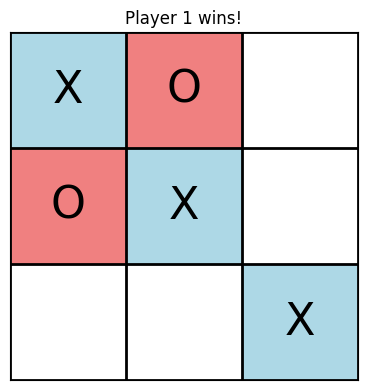

In [ ]:

import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

def check_winner(board):
    board = np.asarray(board)

    if board.shape != (3, 3):
        raise ValueError("The board must have shape (3, 3).")

    if not np.all(np.isin(board, [0, 1, 2])):
        raise ValueError("Board values must be 0, 1, or 2.")

    for player in (1, 2):
        for i in range(3):
            # Check row i
            if np.all(board[i, :] == player):
                return f"Player {player} wins!"

            # Check column i
            if np.all(board[:, i] == player):
                return f"Player {player} wins!"

        # Check the main diagonal
        if np.all(np.diag(board) == player):
            return f"Player {player} wins!"

        # Check the anti-diagonal
        if np.all(np.diag(board[:, ::-1]) == player):
            return f"Player {player} wins!"

    if np.any(board == 0):
        return "Game is still in progress."

    return "The game is a draw."


board = np.array([
    [1, 2, 0],
    [2, 1, 0],
    [0, 0, 1]
])

result = check_winner(board)
print(result)

# Display the board
cmap = ListedColormap(["white", "lightblue", "lightcoral"])

fig, ax = plt.subplots(figsize=(4, 4))
ax.imshow(
    board,
    cmap=cmap,
    vmin=0,
    vmax=2,
    interpolation="nearest"
)

symbols = {0: "", 1: "X", 2: "O"}

for row in range(3):
    for col in range(3):
        ax.text(
            col, row,
            symbols[board[row, col]],
            ha="center",
            va="center",
            fontsize=32,
            color="black"
        )

# Draw cell boundaries
ax.set_xticks(np.arange(-0.5, 3, 1), minor=True)
ax.set_yticks(np.arange(-0.5, 3, 1), minor=True)
ax.grid(which="minor", color="black", linewidth=2)

# Hide axis labels and tick marks
ax.set_xticks([])
ax.set_yticks([])
ax.tick_params(which="minor", bottom=False, left=False)

ax.set_title(result)
plt.tight_layout()
plt.show()